# Field-Driven Shift of the AFM–FM Transition in FeRh
### Spin-1 Ising 모델 Monte Carlo 시뮬레이션 (중간 프로젝트)

> **Question:** 자기장이 변하면 FeRh의 전이온도 $T_t$는 어떻게, 얼마나 변하는가?

**배경.** FeRh는 B2 구조(정육면체 꼭짓점에 Fe, 중심에 Rh)이고, 저온에서는 반강자성(AFM), 상온 근처(약 320–370 K)에서 강자성(FM)이 되는 1차 전이를 보인다(Kouvel & Hartelius 1962). FM이 되면서 자성이 없던 Rh에도 모멘트가 생긴다. 열보조 자기기록, 반강자성 메모리, 자기 냉각에 쓰려면 원하는 온도에서 전이가 일어나도록 전이온도 $T_t$를 조절해야 한다. $T_t$를 움직이는 수단으로 자기장, 변형(strain), 박막 두께가 있고, 이번 중간 프로젝트에서는 가장 단순하게 외부에서 조절할 수 있는 **자기장**부터 살펴본다(변형·두께는 기말). 실제 샘플의 절대 $T_t$보다는 자기장에 따른 변화 자체에 초점을 맞춘다.

**답 (요약).** 자기장은 자화가 있는 FM에만 에너지 이득을 줘서 $T_t$를 낮춘다. 그 크기는 $\Delta M/\Delta S$로 정해지고, 이 모델에서 1 T당 약 24 K다. 실험(약 −8 K/T)보다 약 3배 크다(Step 14 한계).

**약어:** AFM = 반강자성, FM = 강자성, $T_t$ = AFM → FM 전이온도, MC = Monte Carlo, SE = 표준오차(표준편차/$\sqrt{\text{실행 수}}$), mRy = 밀리리드베리(1 mRy = 13.6 meV ≈ 158 K), $\mu_B$ = 보어 마그네톤

**노트북 구성** (발표 슬라이드 순서와 같음)

| 구분 | Step | 슬라이드 |
|---|---|---|
| Model | 1–3 매개변수, 격자, 해밀토니안 | 4–5 |
| Workflow | 4 Metropolis + 집단 이동, 5 가열과 측정, 6 $T_t$ 판정 | 6–8 |
| Validation | 7 에너지 계산, 8 $L=2$ 엄밀해 | 9–10 |
| 본 계산 | 9 온도 × 자기장 스캔 (+ 실제 스핀 배열) | 7 |
| Result | 10 $B=0$ 전이, 11 자기장이 $T_t$를 낮춘다 | 11–12 |
| Interpretation | 12 왜 낮추는가, 13 왜 직선이 아닌가 | 13–14 |
| 정리 | 14 한계, 결론과 다음 단계, 참고문헌 | 15–17 |

**실행 방법.** 위에서부터 모든 셀을 실행(Run All)한다(약 2–5분). 가장 오래 걸리는 본 계산(Step 9, 약 15–25분)은 기본값이 저장된 결과 `ferh_field_scan.npz` 불러오기이고, 파일이 없거나 `RUN_MAIN_SCAN = True`이면 새로 계산한다. seed가 고정돼 있어 다시 계산해도 같은 숫자가 나온다. 그래프는 `figures/` 폴더에 저장된다.

## Step 1. 라이브러리와 매개변수

- `numpy`: 배열 계산, `matplotlib`: 그래프
- `numba`의 `@njit`: 함수 위에 붙이면 **같은 코드를 약 100배 빠르게** 실행해 준다. 계산 내용은 전혀 바뀌지 않으므로, `@njit` 줄을 지워도 결과는 같고 느려지기만 한다.

| 기호 | 값 | 의미 |
|---|---|---|
| $s_i$ | ±1 | Fe 스핀 (위 / 아래) |
| $\sigma_k$ | −1, 0, +1 | Rh 스핀 (0 = 모멘트 없음) |
| $J_{FF}$ | −1.00 mRy | Fe–Fe 교환 (이웃 6개) → AFM 선호 |
| $J_{FR}$ | +2.13 mRy | Fe–Rh 교환 (이웃 8개) → FM 선호 |
| $D_{Rh}$ | −11.10 mRy | Rh 모멘트가 생기는 비용 → 모멘트 0 선호 |
| $\mu_{Fe}$, $\mu_{Rh}$ | 3.2, 0.9 $\mu_B$ | 원자 자기모멘트 (Zeeman 항, **이번에 추가**) |
| $B$ | 0 – 3 T | 외부 자기장 (**이번에 추가**) |

- $J_{FF}$, $J_{FR}$, $D_{Rh}$는 Gruner 등(2003) Table II 값을 **그대로** 쓴다(1 mRy = 13.6 meV ≈ 158 K). 이 값들은 **자기장이 없을 때의 실험 온도들**(Néel 온도, $T_C$, $T_m$)에 맞춰 정해진 값이고, 자기장 의존성은 맞추지 않았다. 따라서 이번에 계산하는 $dT_t/dB$는 모델이 스스로 내놓는 값이다.
- $\mu_{Fe}$, $\mu_{Rh}$는 FM 상의 측정/계산값이다(Lewis et al. 2016 리뷰).

In [1]:
%matplotlib inline
# ↑ 그래프를 노트북(VS Code, Jupyter, Colab) 셀 바로 아래에 표시하라는 명령

import os
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

# 발표용 그래프: 글씨를 크게, 그림은 figures/ 폴더에 저장
plt.rcParams.update({"font.size": 14, "axes.labelsize": 15, "legend.fontsize": 12})
os.makedirs("figures", exist_ok=True)

# --- Gruner et al. (2003) Table II 값 (단위: mRy) ---
J_FF = -1.00       # Fe-Fe 교환상수 (음수 → AFM 선호)
J_FR = 2.13        # Fe-Rh 교환상수 (양수 → FM 선호)
D_RH = -11.10      # Rh 단일 이온 항 (음수 → Rh 모멘트 0 선호)

# --- 자기장 항에 필요한 값 (이번에 새로 추가) ---
MU_FE = 3.2        # Fe 자기모멘트 (단위: 보어 마그네톤 mu_B)
MU_RH = 0.9        # Rh 자기모멘트 (단위: mu_B)

# --- 단위 변환 상수 ---
EV_PER_MRY = 0.013605693122994                  # 1 mRy = 0.0136 eV
KB_MRY_PER_K = 8.617333262e-5 / EV_PER_MRY      # 볼츠만 상수 k_B (mRy/K)
MUB_MRY_PER_T = 5.7883818060e-5 / EV_PER_MRY    # mu_B x 1 Tesla 의 에너지 (mRy)

print(f"k_B = {KB_MRY_PER_K:.3e} mRy/K,  mu_B*(1 T) = {MUB_MRY_PER_T:.3e} mRy")

k_B = 6.334e-03 mRy/K,  mu_B*(1 T) = 4.254e-03 mRy


## Step 2. 격자와 시작 배열

B2(CsCl) 구조: Fe가 단순입방 격자를 이루고, 각 입방체 중심에 Rh가 있다. 코드에서는 `fe[i,j,k]`, `rh[i,j,k]` 두 개의 $L\times L\times L$ 배열로 저장한다. **한 칸 = Fe 1개 + Rh 1개**이고, 본 계산의 $L=6$이면 216칸(원자 432개)이다. 격자 끝은 반대편과 이어 붙인다(주기 경계). $L=6$은 이번 샘플링 방법으로 전이를 안정적으로 관찰할 수 있었던 크기다($L=8$에서는 데울 때 한 상태에 갇히는 실행이 있었다, Step 14 한계).

- Fe 스핀: $s=\pm1$ (위/아래)
- Rh 스핀: $\sigma=-1, 0, +1$ (아래 / 모멘트 없음 / 위)

시작 배열은 저온의 실제 상태인 AFM: Fe를 체스판처럼 $+1,-1$로 번갈아 놓고 Rh는 모두 0. 주기 경계에서 이 패턴이 끊기지 않으려면 $L$이 짝수여야 한다.

In [2]:
def make_afm_state(L):
    # L이 짝수인지 확인 (홀수면 주기 경계에서 AFM 패턴이 깨짐)
    if L < 2 or L % 2:
        raise ValueError("L must be an even integer >= 2")
    # (i+j+k)가 짝수인 자리 → +1, 홀수인 자리 → -1
    parity = np.indices((L, L, L)).sum(axis=0) % 2
    fe = np.where(parity == 0, 1, -1).astype(np.int8)
    rh = np.zeros_like(fe)          # Rh는 모두 0 (모멘트 없음)
    return fe, rh

fe_demo, rh_demo = make_afm_state(4)
print("Fe 배열의 한 층 (k=0):\n", fe_demo[:, :, 0])

Fe 배열의 한 층 (k=0):
 [[ 1 -1  1 -1]
 [-1  1 -1  1]
 [ 1 -1  1 -1]
 [-1  1 -1  1]]


## Step 3. 해밀토니안 (자기장 항 추가)

$$
H=-J_{FF}\sum_{\langle ij\rangle}s_i s_j\;-\;J_{FR}\sum_{\langle ik\rangle}s_i\sigma_k\;-\;D_{Rh}\sum_k\sigma_k^2\;-\;\underbrace{\mu_B B\Big(\mu_{Fe}\sum_i s_i+\mu_{Rh}\sum_k\sigma_k\Big)}_{\text{새로 추가한 Zeeman 항}}
$$

항마다 선호하는 배열이 다르다. 이 모델은 **AFM과 FM의 줄다리기**이고, 자기장은 FM 쪽에 힘을 보탠다.

| 항 | 이웃 | 선호하는 배열 |
|---|---|---|
| $-J_{FF}\sum s_i s_j$ ($J_{FF}<0$) | Fe마다 Fe 6개 | 이웃 Fe가 반대 방향 → **AFM** |
| $-J_{FR}\sum s_i\sigma_k$ ($J_{FR}>0$) | Fe마다 Rh 8개 | Fe와 Rh가 같은 방향 → **FM** |
| $-D_{Rh}\sum\sigma_k^2$ ($D_{Rh}<0$) | Rh 자신 | Rh 모멘트 꺼짐($\sigma=0$) |
| Zeeman (이번에 추가) | 원자 자신 | 자기장 방향 정렬 → **FM** |

- **왜 자기장 항은 이것 하나인가:** 이 모델의 자유도는 스핀뿐이라, 자기장이 스핀에 작용하는 길은 Zeeman 에너지 $-\mu\cdot B$ 하나다. 1 T의 Zeeman 에너지(Fe당 약 0.19 meV)는 교환 에너지(수–수십 meV)의 약 1%라서 자기장이 교환 상수를 바꾸는 효과는 무시했다. 자기장에 의한 격자 변화(자기변형)는 격자 자유도가 없어서 넣을 수 없고, 한계로 남긴다.

**바닥상태 에너지 비교 (칸 하나당, $B=0$):**
- AFM ($\sigma=0$): $3J_{FF} = -3.00$ mRy
- FM ($\sigma=+1$): $-3J_{FF}-8J_{FR}-D_{Rh} = -2.94$ mRy

두 상태의 차이는 0.06 mRy(약 9 K)뿐이다. 그래서 온도와 자기장에 매우 민감하다.

아래 함수들:
- `total_energy`: 전체 에너지 (검증용, 느림)
- `delta_energy_fe`, `delta_energy_rh`: 스핀 **하나**를 바꿀 때의 에너지 변화 (Monte Carlo에서 사용, 빠름. 바뀐 원자 주변만 계산)

In [3]:
# ---------- 이웃 합을 구하는 보조 함수들 ----------
# (i+1) % L : 격자 끝을 넘어가면 반대편 처음으로 돌아옴 (주기 경계 조건)

@njit
def sum_fe_neighbors_of_fe(fe, i, j, k):
    # Fe 하나 주변의 Fe 6개 (+x, -x, +y, -y, +z, -z) 스핀 합
    L = fe.shape[0]
    return (fe[(i + 1) % L, j, k] + fe[(i - 1) % L, j, k]
            + fe[i, (j + 1) % L, k] + fe[i, (j - 1) % L, k]
            + fe[i, j, (k + 1) % L] + fe[i, j, (k - 1) % L])

@njit
def sum_rh_neighbors_of_fe(rh, i, j, k):
    # Fe 하나를 둘러싼 Rh 8개 (입방체 8개의 중심)의 스핀 합
    L = rh.shape[0]
    total = 0
    for di in range(2):
        for dj in range(2):
            for dk in range(2):
                total += rh[(i - di) % L, (j - dj) % L, (k - dk) % L]
    return total

@njit
def sum_fe_neighbors_of_rh(fe, i, j, k):
    # Rh 하나를 둘러싼 Fe 8개 (입방체의 꼭짓점)의 스핀 합
    L = fe.shape[0]
    total = 0
    for di in range(2):
        for dj in range(2):
            for dk in range(2):
                total += fe[(i + di) % L, (j + dj) % L, (k + dk) % L]
    return total


# ---------- 전체 에너지 ----------
@njit
def total_energy(fe, rh, B):
    # B: 자기장 (Tesla)
    L = fe.shape[0]
    energy = 0.0
    for i in range(L):
        for j in range(L):
            for k in range(L):
                s_fe = fe[i, j, k]
                s_rh = rh[i, j, k]
                # Fe-Fe: 같은 결합을 두 번 세지 않도록 +x, +y, +z 방향만 더함
                energy -= J_FF * s_fe * (fe[(i + 1) % L, j, k] + fe[i, (j + 1) % L, k] + fe[i, j, (k + 1) % L])
                # Fe-Rh: 각 Fe와 주변 Rh 8개
                energy -= J_FR * s_fe * sum_rh_neighbors_of_fe(rh, i, j, k)
                # Rh 단일 이온 항
                energy -= D_RH * s_rh ** 2
                # Zeeman 항 (새로 추가)
                energy -= MUB_MRY_PER_T * B * (MU_FE * s_fe + MU_RH * s_rh)
    return energy


# ---------- 스핀 하나를 바꿀 때의 에너지 변화 ----------
@njit
def delta_energy_fe(fe, rh, i, j, k, B):
    # Fe 스핀 s → -s 로 뒤집을 때: dE = 2 s × (주변이 만드는 유효 자기장)
    s = fe[i, j, k]
    local_field = (J_FF * sum_fe_neighbors_of_fe(fe, i, j, k)
                   + J_FR * sum_rh_neighbors_of_fe(rh, i, j, k)
                   + MUB_MRY_PER_T * B * MU_FE)          # Zeeman 기여
    return 2.0 * s * local_field

@njit
def delta_energy_rh(fe, rh, i, j, k, new_state, B):
    # Rh 스핀을 old → new 로 바꿀 때의 에너지 변화
    old_state = rh[i, j, k]
    change = new_state - old_state
    onsite_change = -D_RH * (new_state ** 2 - old_state ** 2)
    exchange_change = -J_FR * change * sum_fe_neighbors_of_rh(fe, i, j, k)
    zeeman_change = -MUB_MRY_PER_T * B * MU_RH * change  # Zeeman 기여
    return onsite_change + exchange_change + zeeman_change

## Step 4. Workflow ①: Metropolis Monte Carlo + 집단 이동

**의사코드:**
```
원자 하나를 무작위로 골라 스핀을 바꿔보기 제안
ΔE 계산 (이웃 원자만 고려)
ΔE ≤ 0 이면 항상 채택
ΔE > 0 이면 확률 p_acc = exp(-ΔE / k_B T) 로 채택
(거절되면 원래 상태 유지)
```
$$p_{\mathrm{acc}}=\min\left[1,\;e^{-\Delta E/k_BT}\right]\qquad\text{(Metropolis et al. 1953)}$$

한 번의 sweep = Fe $L^3$번 + Rh $L^3$번 제안. **온도는 $p_{\mathrm{acc}}$에만 들어간다.** 온도가 높을수록 에너지가 높은 배열도 받아들여진다.

**집단 이동(global move):** AFM ↔ FM처럼 격자 전체가 바뀌는 1차 전이는 스핀 하나씩 바꾸는 것만으로는 너무 느리다(한 상태에 갇힘). 그래서 sweep마다 한 번씩 "Fe 한쪽 부분격자 통째 뒤집기 + Rh 전체 순환"을 제안한다. 이 제안도 같은 해밀토니안과 Metropolis 규칙으로 채택 여부를 정하므로 볼츠만 분포는 바뀌지 않는다(대칭 제안, Hastings 1970). Gruner 등도 같은 이유로 global update를 썼다. 실제로 맞는지는 Step 8에서 엄밀해로 확인한다.

In [4]:
@njit
def cycle_rh(old, shift):
    # Rh 값을 -1 → 0 → +1 → -1 → ... 순서로 shift칸 이동
    # 예) old=-1, shift=1 → 0     old=+1, shift=1 → -1     old=0, shift=2 → -1
    return (old + 1 + shift) % 3 - 1


@njit
def local_sweep(fe, rh, T, B):
    # 한 sweep: Fe L^3번 + Rh L^3번 Metropolis 제안
    L = fe.shape[0]
    N_cell = L ** 3
    beta = 1.0 / (KB_MRY_PER_K * T)

    # (1) Fe 스핀 뒤집기 제안
    for _ in range(N_cell):
        i = np.random.randint(0, L)
        j = np.random.randint(0, L)
        k = np.random.randint(0, L)
        dE = delta_energy_fe(fe, rh, i, j, k, B)
        if dE <= 0.0 or np.random.random() < np.exp(-beta * dE):   # Metropolis 규칙
            fe[i, j, k] *= -1

    # (2) Rh 상태 바꾸기 제안: 한 칸 또는 두 칸 순환 → 현재 값이 아닌 나머지 두 값 중 하나
    for _ in range(N_cell):
        i = np.random.randint(0, L)
        j = np.random.randint(0, L)
        k = np.random.randint(0, L)
        new = cycle_rh(rh[i, j, k], np.random.randint(1, 3))   # randint(1,3)은 1 또는 2
        dE = delta_energy_rh(fe, rh, i, j, k, new, B)
        if dE <= 0.0 or np.random.random() < np.exp(-beta * dE):
            rh[i, j, k] = new


@njit
def global_phase_move(fe, rh, T, B):
    # 집단 이동: 격자 전체를 한 번에 바꾸는 제안 (AFM <-> FM 이동을 돕기 위함)
    L = fe.shape[0]
    beta = 1.0 / (KB_MRY_PER_K * T)
    old_energy = total_energy(fe, rh, B)

    trial_fe = fe.copy()
    trial_rh = rh.copy()
    flip_even = np.random.random() < 0.5          # 짝수 자리 Fe를 뒤집을지
    flip_odd = np.random.random() < 0.5           # 홀수 자리 Fe를 뒤집을지
    shift = np.random.randint(1, 3)               # 모든 Rh를 1칸 또는 2칸 순환

    for i in range(L):
        for j in range(L):
            for k in range(L):
                even_site = (i + j + k) % 2 == 0
                if (even_site and flip_even) or ((not even_site) and flip_odd):
                    trial_fe[i, j, k] *= -1
                trial_rh[i, j, k] = cycle_rh(trial_rh[i, j, k], shift)

    dE = total_energy(trial_fe, trial_rh, B) - old_energy
    if dE <= 0.0 or np.random.random() < np.exp(-beta * dE):
        fe[:, :, :] = trial_fe
        rh[:, :, :] = trial_rh


@njit
def mc_sweep(fe, rh, T, B):
    local_sweep(fe, rh, T, B)
    global_phase_move(fe, rh, T, B)

## Step 5. Workflow ②: 가열 스캔과 측정량

AFM에서 시작해 **150 → 350 K를 5 K 간격으로** 데운다. 직전 온도의 마지막 배열이 다음 온도의 시작 배열이다. 온도마다 300 sweep은 평형을 맞추는 데 쓰고 버린 뒤, 2 sweep마다 배열을 하나씩 측정해 **표본 1000개**를 평균한다.

측정량 (질서도):
- **FM 질서도** $m_{FM}=\left|\dfrac{3\sum s_i+\sum\sigma_k}{4N}\right|$: 모두 위를 향하면 1 (Fe:Rh 모멘트 비율 약 3:1로 가중)
- **AFM 질서도** $m_{AF}=\left|\dfrac{\sum_i \eta_i s_i}{N}\right|$, $\eta_i=\pm1$ (체스판 부호): 완벽한 AFM이면 1
- **Rh 자성 분율** $f_{Rh}$: Rh가 $\pm1$인 비율

In [5]:
@njit
def order_parameters(fe, rh):
    # 반환값: (FM 질서도, AFM 질서도, Rh 자성 분율)
    L = fe.shape[0]
    N_cell = L ** 3
    sum_fe = 0.0
    sum_rh = 0.0
    staggered_fe = 0.0
    magnetic_rh = 0.0
    for i in range(L):
        for j in range(L):
            for k in range(L):
                sum_fe += fe[i, j, k]
                sum_rh += rh[i, j, k]
                eta = 1.0 if (i + j + k) % 2 == 0 else -1.0   # 체커보드 부호
                staggered_fe += eta * fe[i, j, k]
                magnetic_rh += rh[i, j, k] ** 2               # Rh가 ±1이면 1, 0이면 0
    m_fm = abs(3.0 * sum_fe + 1.0 * sum_rh) / (4.0 * N_cell)
    m_af = abs(staggered_fe) / N_cell
    rh_fraction = magnetic_rh / N_cell
    return m_fm, m_af, rh_fraction


@njit
def measure_temperature(fe, rh, T, B, seed, n_equil, n_samples, stride):
    # 한 온도에서: 평형화 n_equil sweep → stride sweep마다 측정을 n_samples번 → 평균
    np.random.seed(seed)
    for _ in range(n_equil):
        mc_sweep(fe, rh, T, B)
    total = np.zeros(3)
    for _ in range(n_samples):
        for _ in range(stride):
            mc_sweep(fe, rh, T, B)
        m_fm, m_af, rh_fraction = order_parameters(fe, rh)
        total[0] += m_fm
        total[1] += m_af
        total[2] += rh_fraction
    return total / n_samples


def heating_scan(L, temperatures, B, seed, n_equil=300, n_samples=300, stride=2):
    # AFM에서 시작해 온도를 차례로 올림. 직전 온도의 마지막 배열이 다음 온도의 시작 배열.
    fe, rh = make_afm_state(L)
    results = np.empty((len(temperatures), 3))
    for n, T in enumerate(temperatures):
        results[n] = measure_temperature(fe, rh, T, B, seed + n, n_equil, n_samples, stride)
    return results

## Step 6. Workflow ③: 전이온도 $T_t$ 판정

**정의:** 온도를 올리며 $m_{FM}$이 $m_{AF}$를 추월하는 온도, 즉 $m_{FM}-m_{AF}$의 부호가 $-$에서 $+$로 바뀌는 지점. 두 온도 격자점 사이는 직선으로 이어서(선형 보간) 교차점을 구한다.

**독립 실행(seed)마다 $T_t$를 하나씩 구하고**, 자기장 0–3 T(0.25 T 간격 13개) × 독립 실행 10번을 계산한다. 에러바는 실행 사이의 표준오차(SE = 표준편차/$\sqrt{\text{실행 수}}$)다.

In [6]:
def find_transition(temperatures, m_fm, m_af):
    # m_FM - m_AF 가 처음으로 음수 → 양수가 되는 구간을 찾아 선형 보간
    d = m_fm - m_af
    for n in range(len(temperatures) - 1):
        if d[n] <= 0 < d[n + 1]:
            T1, T2 = temperatures[n], temperatures[n + 1]
            return T1 + (T2 - T1) * (-d[n]) / (d[n + 1] - d[n])
    return np.nan    # 교차점이 온도 범위 안에 없으면 NaN

## Step 7. Validation ①: 에너지 계산

시뮬레이션은 스핀 하나를 바꿀 때마다 전체 에너지를 다시 계산하지 않고, 바뀐 원자 주변만으로 에너지 변화 $\Delta E$를 계산한다(Step 3의 `delta_energy_*`). 이 빠른 계산이 정말 맞는지, **같은 변화를 전체 에너지로 직접 다시 계산한 값과 비교**한다.

- 본 계산과 같은 $L=6$ 격자, 계산에 쓰는 자기장(0, 0.5, 1, 2, 3 T)마다 무작위 배열 200개
- 이 등식은 배열과 자기장에 상관없이 **항상 정확히** 성립해야 하므로, 이웃 찾기나 부호가 하나라도 틀리면 큰 차이로 드러난다.
- 완벽한 AFM, FM 상태의 에너지도 손계산(Step 3)과 비교한다.

→ "에너지를 제대로 계산하고 있는가?"를 확인하는 검증이다.

In [7]:
# ---------- 검증 ①: 빠른 계산(delta) == 느린 계산(전체 에너지 차이)? ----------
# 본 계산과 같은 L=6 격자에서, 계산에 쓰는 자기장마다 무작위 배열 200개씩 확인한다.
# 이 등식은 배열과 자기장에 상관없이 "항상 정확히" 성립해야 하므로, 하나라도 틀리면 큰 차이로 드러난다.
rng = np.random.default_rng(0)
n_checks = 200
B_checks = [0.0, 0.5, 1.0, 2.0, 3.0]

print(" B (T) | 확인한 배열 수 | Fe 뒤집기 최대 차이 (mRy) | Rh 바꾸기 최대 차이 (mRy)")
for B_test in B_checks:
    max_fe = 0.0
    max_rh = 0.0
    for _ in range(n_checks):
        fe_check = rng.choice(np.array([-1, 1], dtype=np.int8), size=(6, 6, 6))
        rh_check = rng.choice(np.array([-1, 0, 1], dtype=np.int8), size=(6, 6, 6))
        i, j, k = rng.integers(0, 6, size=3)
        E_before = total_energy(fe_check, rh_check, B_test)

        # (a) Fe 하나 뒤집기
        fe_trial = fe_check.copy()
        fe_trial[i, j, k] *= -1
        diff_fe = (total_energy(fe_trial, rh_check, B_test) - E_before) - delta_energy_fe(fe_check, rh_check, i, j, k, B_test)

        # (b) Rh 하나를 다른 값으로 바꾸기
        new = rng.choice([v for v in (-1, 0, 1) if v != rh_check[i, j, k]])
        rh_trial = rh_check.copy()
        rh_trial[i, j, k] = new
        diff_rh = (total_energy(fe_check, rh_trial, B_test) - E_before) - delta_energy_rh(fe_check, rh_check, i, j, k, new, B_test)

        max_fe = max(max_fe, abs(diff_fe))
        max_rh = max(max_rh, abs(diff_rh))

    assert max(max_fe, max_rh) < 1e-9
    print(f"{B_test:6.1f} | {n_checks:14d} | {max_fe:24.1e} | {max_rh:.1e}")
print("모든 자기장에서 통과: 차이는 컴퓨터 반올림 오차(1e-12 수준)뿐이다.")

# 바닥상태 에너지 차이도 직접 확인
fe_afm, rh_afm = make_afm_state(4)
fe_fm = np.ones_like(fe_afm); rh_fm = np.ones_like(rh_afm)
N = 4 ** 3
print(f"E_AFM/셀 = {total_energy(fe_afm, rh_afm, 0.0)/N:.3f} mRy,  E_FM/셀 = {total_energy(fe_fm, rh_fm, 0.0)/N:.3f} mRy")

 B (T) | 확인한 배열 수 | Fe 뒤집기 최대 차이 (mRy) | Rh 바꾸기 최대 차이 (mRy)


   0.0 |            200 |                  4.9e-13 | 7.7e-13
   0.5 |            200 |                  9.5e-13 | 8.6e-13
   1.0 |            200 |                  7.4e-13 | 1.1e-12
   2.0 |            200 |                  5.4e-13 | 8.7e-13


   3.0 |            200 |                  1.1e-12 | 1.0e-12
모든 자기장에서 통과: 차이는 컴퓨터 반올림 오차(1e-12 수준)뿐이다.
E_AFM/셀 = -3.000 mRy,  E_FM/셀 = -2.940 mRy


## Step 8. Validation ②: Monte Carlo가 정확한 답(엄밀해)을 재현하는가? ($L=2$)

에너지를 정확히 계산하더라도, Metropolis + 집단 이동이 상태들을 잘못된 비율로 뽑으면 결과가 틀린다. 그래서 **정답을 정확히 구할 수 있는 작은 격자**에서 비교한다.

**엄밀해란?** 가능한 배열을 **하나도 빠짐없이** 모두 더해서 구한 정확한 열평균이다.
$$\langle A\rangle_{\text{exact}}=\frac{\sum_{\text{모든 배열 } c} A_c\,e^{-E_c/k_BT}}{\sum_{c} e^{-E_c/k_BT}}$$
무작위성이 전혀 없으므로 "정답"으로 쓸 수 있다.

**왜 $L=2$인가?** $L=2$ 격자는 Fe 8개($2^8$가지), Rh 8개($3^8$가지)라 배열이 $1{,}679{,}616$개뿐이어서 전부 계산할 수 있다. 본 계산의 $L=6$은 약 $10^{168}$개라 불가능하다. 격자 크기만 다르고 Metropolis 규칙, 에너지 계산, 상태 업데이트는 **같은 코드**이므로, $L=2$에서 정답을 재현하면 샘플링 알고리즘 자체가 올바르다는 증거가 된다.

**비교 방법**
- 엄밀해를 **온도 61개의 매끄러운 곡선**으로 그리고, Monte Carlo 점(온도 5개, 독립 실행 8번)을 그 위에 올린다.
- 아래 그래프에 **(MC − 엄밀해) / 표준오차**를 따로 그린다. 통계적으로 일치하면 대부분의 점이 **±2 띠 안**(약 95%)에 들어가야 한다.
- 자기장 항까지 확인하도록 **$B = 0$과 $B = 2$ T** 모두 비교한다.

참고: $L=2$는 원자 16개짜리 격자라 값 자체(예: 150 K에서 $m_{FM}\approx0.4$)에는 물리적 의미가 없다. 여기서는 **두 계산 방법의 답이 같은지**만 본다.

In [8]:
@njit
def enumerate_all_states(B):
    # L=2 격자의 모든 배열에 대해 에너지와 질서도를 한 번씩 계산해 둔다 (온도와 무관하므로 한 번만)
    fe = np.empty((2, 2, 2), np.int8)
    rh = np.empty((2, 2, 2), np.int8)
    n_states = 2 ** 8 * 3 ** 8
    energies = np.empty(n_states)
    observables = np.empty((n_states, 3))
    for code in range(n_states):
        # 정수 code를 Fe 8자리(2진법) + Rh 8자리(3진법)로 해석해 배열 하나를 만든다
        c = code
        for s in range(8):
            fe.flat[s] = 1 if c % 2 == 0 else -1
            c //= 2
        for s in range(8):
            rh.flat[s] = (c % 3) - 1
            c //= 3
        energies[code] = total_energy(fe, rh, B)
        m_fm, m_af, rh_fraction = order_parameters(fe, rh)
        observables[code, 0] = m_fm
        observables[code, 1] = m_af
        observables[code, 2] = rh_fraction
    return energies, observables


def exact_average(energies, observables, T):
    # 볼츠만 가중 평균. 최저 에너지를 빼서 exp가 너무 커지지 않게 한다 (평균값은 변하지 않음)
    weights = np.exp(-(energies - energies.min()) / (KB_MRY_PER_K * T))
    return weights @ observables / weights.sum()


exact_fields = [0.0, 2.0]
T_fine = np.linspace(100.0, 700.0, 61)                    # 엄밀해 곡선용 촘촘한 온도
T_mc = np.array([150.0, 250.0, 300.0, 400.0, 600.0])     # Monte Carlo로 비교할 온도
n_check_runs = 8

exact_curve, exact_at_mc, mc_mean, mc_se = {}, {}, {}, {}
for B in exact_fields:
    energies, observables = enumerate_all_states(B)
    exact_curve[B] = np.array([exact_average(energies, observables, T) for T in T_fine])
    exact_at_mc[B] = np.array([exact_average(energies, observables, T) for T in T_mc])

    runs = np.empty((n_check_runs, len(T_mc), 3))
    for r in range(n_check_runs):
        for t, T in enumerate(T_mc):
            fe, rh = make_afm_state(2)
            runs[r, t] = measure_temperature(fe, rh, T, B, 10 + 100 * r + t, 2000, 20000, 2)
    mc_mean[B] = runs.mean(axis=0)
    mc_se[B] = runs.std(axis=0, ddof=1) / np.sqrt(n_check_runs)

names = ["m_FM ", "m_AF ", "Rh분율"]
z_all = []
print(" B (T) | T (K) | 양     | 엄밀해  | MC 평균 ± SE      | (MC−엄밀해)/SE")
for B in exact_fields:
    for t, T in enumerate(T_mc):
        for q in range(3):
            z = (mc_mean[B][t, q] - exact_at_mc[B][t, q]) / mc_se[B][t, q]
            z_all.append(z)
            print(f"{B:6.1f} | {T:5.0f} | {names[q]} | {exact_at_mc[B][t, q]:.4f}  | "
                  f"{mc_mean[B][t, q]:.4f} ± {mc_se[B][t, q]:.4f}  | {z:+.1f}")
z_all = np.array(z_all)
print(f"\n비교한 값 {len(z_all)}개 중 |차이/SE| < 2인 비율: {np.mean(np.abs(z_all) < 2):.0%},  최대 |차이/SE| = {np.abs(z_all).max():.1f}")

 B (T) | T (K) | 양     | 엄밀해  | MC 평균 ± SE      | (MC−엄밀해)/SE
   0.0 |   150 | m_FM  | 0.3797  | 0.3773 ± 0.0011  | -2.1
   0.0 |   150 | m_AF  | 0.6201  | 0.6225 ± 0.0011  | +2.1
   0.0 |   150 | Rh분율 | 0.3792  | 0.3768 ± 0.0011  | -2.1
   0.0 |   250 | m_FM  | 0.4638  | 0.4627 ± 0.0025  | -0.5
   0.0 |   250 | m_AF  | 0.5334  | 0.5345 ± 0.0026  | +0.4
   0.0 |   250 | Rh분율 | 0.4561  | 0.4550 ± 0.0024  | -0.4
   0.0 |   300 | m_FM  | 0.5030  | 0.5055 ± 0.0017  | +1.4
   0.0 |   300 | m_AF  | 0.4907  | 0.4882 ± 0.0017  | -1.4
   0.0 |   300 | Rh분율 | 0.4877  | 0.4899 ± 0.0016  | +1.3
   0.0 |   400 | m_FM  | 0.5535  | 0.5550 ± 0.0023  | +0.6
   0.0 |   400 | m_AF  | 0.4243  | 0.4228 ± 0.0023  | -0.6
   0.0 |   400 | Rh분율 | 0.5178  | 0.5187 ± 0.0020  | +0.4
   0.0 |   600 | m_FM  | 0.5153  | 0.5186 ± 0.0018  | +1.8
   0.0 |   600 | m_AF  | 0.3892  | 0.3860 ± 0.0016  | -2.0
   0.0 |   600 | Rh분율 | 0.4557  | 0.4583 ± 0.0014  | +1.9
   2.0 |   150 | m_FM  | 0.3898  | 0.3895 ± 0.0013  | -0.2

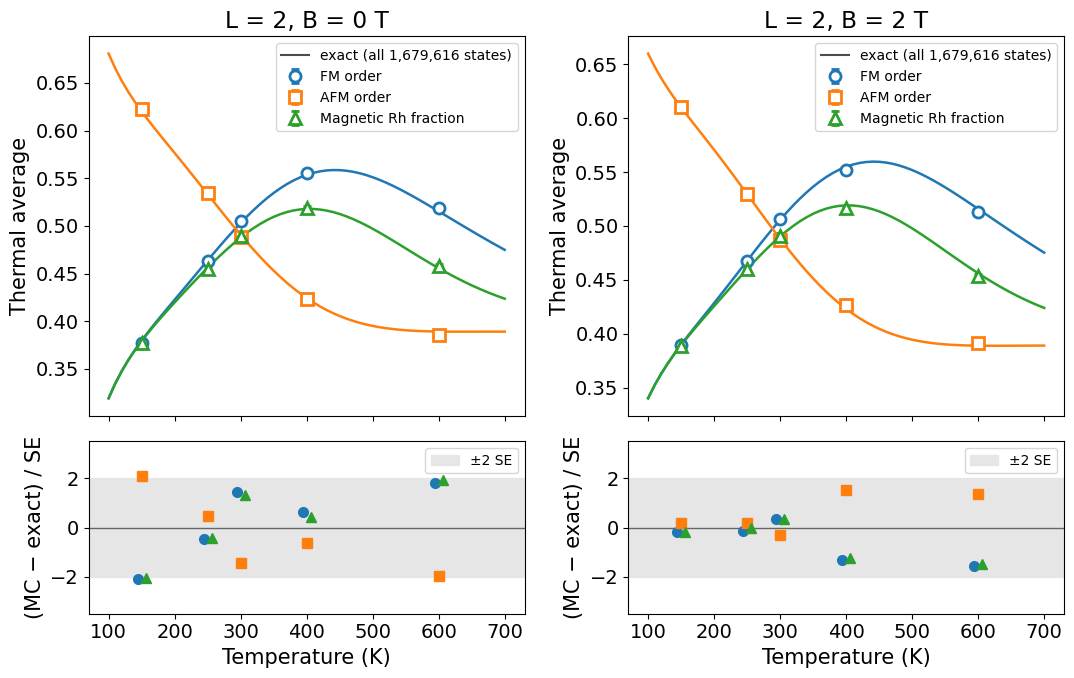

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})
labels = ["FM order", "AFM order", "Magnetic Rh fraction"]
markers = ["o", "s", "^"]
for col, B in enumerate(exact_fields):
    ax = axes[0, col]
    for q in range(3):
        ax.plot(T_fine, exact_curve[B][:, q], "-", color=f"C{q}", lw=1.8)
        ax.errorbar(T_mc, mc_mean[B][:, q], yerr=mc_se[B][:, q], fmt=markers[q], color=f"C{q}",
                    ms=8, mfc="white", mew=2, capsize=3, label=labels[q])
    ax.plot([], [], "-", color="0.3", label="exact (all 1,679,616 states)")
    ax.set(title=f"L = 2, B = {B:.0f} T", ylabel="Thermal average")
    ax.legend(fontsize=10)

    ax = axes[1, col]
    ax.axhspan(-2, 2, color="0.9", label="±2 SE")
    ax.axhline(0, color="0.4", lw=1)
    for q in range(3):
        z = (mc_mean[B][:, q] - exact_at_mc[B][:, q]) / mc_se[B][:, q]
        ax.plot(T_mc + (q - 1) * 6, z, markers[q], color=f"C{q}", ms=7)
    ax.set(xlabel="Temperature (K)", ylabel="(MC − exact) / SE", ylim=(-3.5, 3.5))
    ax.legend(fontsize=10, loc="upper right")
fig.tight_layout()
plt.savefig("figures/fig1_validation_exact.png", dpi=300, bbox_inches="tight")
plt.show()

**판정:** 위 그래프에서 Monte Carlo 점(속이 빈 표시)이 엄밀해 곡선 위에 놓이고, 아래 그래프에서 차이가 ±2 표준오차 띠 안에 들어오면 **통계적으로 일치**한다. 무작위 오차만 있다면 약 95%가 ±2 안에 들어오므로, 몇 개가 경계(±2) 근처에 있는 것은 정상이다. 또 같은 온도의 세 값($m_{FM}$, $m_{AF}$, Rh 분율)은 서로 연동돼 함께 움직이므로(위 그래프에서 세 표시가 같이 위아래로 움직임), 실제로 독립적인 비교는 "온도 5개 × 자기장 2개 = 10개"로 봐야 한다. 자기장이 있을 때($B=2$ T)도 일치하면, 자기장 항을 포함한 샘플링까지 올바르다는 뜻이다.

→ "Monte Carlo가 올바른 평형분포를 샘플링하고 있는가?"를 확인하는 검증이다.

## Step 9. 본 계산: 온도 × 자기장 스캔

- 격자 $L=6$ (216칸), 온도 150–350 K를 5 K 간격으로 (모델 $T_t$ 약 200–290 K가 범위 안)
- 자기장 $B = 0$ – 3 T를 **0.25 T 간격**으로 13개 (곡선 모양을 보기 위해 촘촘하게)
- 자기장마다 서로 다른 seed로 **독립 실행 10번** (5번으로는 0.25 T 간격의 변화보다 통계 잡음이 큼)
- 각 온도: 평형화 300 sweep, 그 뒤 2 sweep마다 측정해 1000개 표본

**실행 시간:** 일반 노트북에서 약 15–25분이다. 그래서 기본값은 저장된 결과(`ferh_field_scan.npz`) 불러오기이고, 파일이 없으면 새로 계산한다. 다시 계산하려면 `RUN_MAIN_SCAN = True`로 바꾼다.

In [10]:
L = 6
temperatures = np.arange(150.0, 351.0, 5.0)
fields = np.arange(0.0, 3.01, 0.25)              # Tesla: 0, 0.25, 0.5, ..., 3.0
seeds = [100, 300, 500, 700, 900, 1100, 1300, 1500, 1700, 1900]
N_EQUIL = 300       # 온도마다 버리는 평형화 sweep 수
N_SAMPLES = 1000    # 온도마다 모으는 표본 수

RUN_MAIN_SCAN = False   # True: 약 15–25분 걸려 다시 계산 / False: 저장된 결과 불러오기

if RUN_MAIN_SCAN or not os.path.exists("ferh_field_scan.npz"):
    # ----- 직접 계산 -----
    # scans[b, r, n, q]: 자기장 b, 실행 r, 온도 n, 측정량 q (0=FM, 1=AFM, 2=Rh분율)
    scans = np.empty((len(fields), len(seeds), len(temperatures), 3))
    T_t = np.empty((len(fields), len(seeds)))        # 실행마다 구한 전이온도

    for b, B in enumerate(fields):
        for r, seed in enumerate(seeds):
            # seed: 실행(seed)과 자기장마다 겹치지 않는 난수 출발점 (온도 번호 0–40은 heating_scan 안에서 더해짐)
            scans[b, r] = heating_scan(L, temperatures, B, seed * 10000 + int(round(4 * B)) * 100,
                                       n_equil=N_EQUIL, n_samples=N_SAMPLES)
            T_t[b, r] = find_transition(temperatures, scans[b, r, :, 0], scans[b, r, :, 1])
        print(f"B = {B:4.2f} T: 실행별 T_t = {np.round(T_t[b], 1)} K")

    np.savez("ferh_field_scan.npz", L=L, temperatures=temperatures, fields=fields,
             seeds=seeds, scans=scans, T_t=T_t)
    print("본 계산을 새로 해서 ferh_field_scan.npz에 저장했다.")
else:
    # ----- 저장된 결과 불러오기 (위와 같은 설정으로 계산한 결과) -----
    saved = np.load("ferh_field_scan.npz")
    assert np.allclose(saved["fields"], fields) and np.allclose(saved["temperatures"], temperatures)
    scans, T_t = saved["scans"], saved["T_t"]
    print("저장된 본 계산 결과(ferh_field_scan.npz)를 불러왔다. 다시 계산하려면 RUN_MAIN_SCAN = True")
    for b, B in enumerate(fields):
        print(f"B = {B:4.2f} T: 실행별 T_t = {np.round(T_t[b], 1)} K")

저장된 본 계산 결과(ferh_field_scan.npz)를 불러왔다. 다시 계산하려면 RUN_MAIN_SCAN = True
B = 0.00 T: 실행별 T_t = [283.  282.8 293.6 285.4 288.  289.3 292.5 291.  286.  292. ] K
B = 0.25 T: 실행별 T_t = [288.3 290.7 290.6 293.4 295.8 294.7 281.4 275.  292.4 283.1] K
B = 0.50 T: 실행별 T_t = [282.4 296.8 289.3 287.2 280.  284.7 282.3 282.1 290.6 273.2] K
B = 0.75 T: 실행별 T_t = [277.  281.5 277.7 278.4 276.2 280.5 285.8 274.8 273.9 277.5] K
B = 1.00 T: 실행별 T_t = [266.9 277.8 276.9 275.3 272.1 267.7 264.  274.1 268.7 280.3] K
B = 1.25 T: 실행별 T_t = [270.5 269.  267.7 263.3 264.4 263.8 268.3 272.7 261.7 266.6] K
B = 1.50 T: 실행별 T_t = [259.3 259.4 258.  259.9 249.7 259.4 259.3 260.6 261.8 258.5] K
B = 1.75 T: 실행별 T_t = [253.6 251.4 246.9 249.7 256.2 247.4 255.8 243.7 248.  249.3] K
B = 2.00 T: 실행별 T_t = [252.5 247.8 239.  247.8 247.6 246.5 245.7 246.7 250.3 247.2] K
B = 2.25 T: 실행별 T_t = [230.8 233.4 234.6 240.2 238.4 237.3 241.3 233.7 233.6 228.9] K
B = 2.50 T: 실행별 T_t = [230.  227.1 219.3 226.9 232.4 223.  224.8 224.9

### Step 9-2. 실제 스핀 배열 들여다보기

숫자만 보면 감이 안 오므로, 실제 시뮬레이션 배열의 한 층($k=0$)을 세 온도에서 그린다.
- 큰 화살표: Fe (빨강 = 위, 파랑 = 아래)
- 작은 표시: Rh (초록 화살표 = 모멘트 있음, 회색 점 = 모멘트 없음)

200 K에서는 체스판 AFM, 330 K에서는 모두 같은 방향이고 Rh에 모멘트가 생긴다.

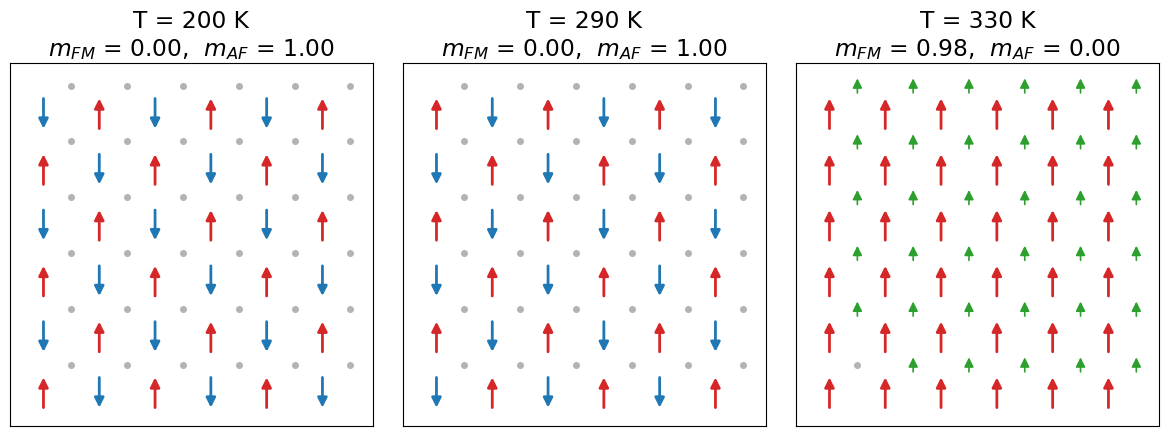

In [11]:
snap_temperatures = [200.0, 290.0, 330.0]
fe, rh = make_afm_state(L)
snapshots = {}
for n, T in enumerate(temperatures):
    measure_temperature(fe, rh, T, 0.0, 777000 + n, N_EQUIL, 50, 2)   # 데우면서 진행
    if T in snap_temperatures:
        snapshots[T] = (fe.copy(), rh.copy())                           # 그 순간의 배열 저장


def draw_layer(ax, fe, rh, k=0):
    L = fe.shape[0]
    for i in range(L):
        for j in range(L):
            # Fe: 격자점 (i, j)에 큰 화살표
            s = fe[i, j, k]
            color = "C3" if s > 0 else "C0"
            ax.annotate("", xy=(i, j + 0.32 * s), xytext=(i, j - 0.32 * s),
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=2))
            # Rh: 입방체 중심 (i+0.5, j+0.5)에 작은 표시
            r = rh[i, j, k]
            if r == 0:
                ax.plot(i + 0.5, j + 0.5, "o", color="0.7", markersize=4)
            else:
                ax.annotate("", xy=(i + 0.5, j + 0.5 + 0.18 * r), xytext=(i + 0.5, j + 0.5 - 0.18 * r),
                            arrowprops=dict(arrowstyle="-|>", color="C2", lw=1.2))
    ax.set_xlim(-0.6, L - 0.1)
    ax.set_ylim(-0.6, L - 0.1)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, T in zip(axes, snap_temperatures):
    fe_s, rh_s = snapshots[T]
    m_fm, m_af, rh_frac = order_parameters(fe_s, rh_s)
    draw_layer(ax, fe_s, rh_s)
    ax.set_title(f"T = {T:.0f} K\n$m_{{FM}}$ = {m_fm:.2f},  $m_{{AF}}$ = {m_af:.2f}")
fig.tight_layout()
plt.savefig("figures/fig_snapshots.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 10. 결과 ①: $B=0$에서의 AFM → FM 전이

낮은 온도에서는 AFM 질서도 ≈ 1이고, 288 K 근처에서 FM 질서도가 AFM 질서도를 추월한다. 초록색 Rh 자성 분율이 FM과 **함께** 커진다. 즉 이 모델은 "Rh 모멘트가 생기면서 FM이 되는" FeRh의 전이를 재현한다. Error bar는 10번 독립 실행의 표준오차.

$T_t$ = 288 ± 1 K로 실험(약 320–370 K)보다 약간 낮지만, 이번 질문은 절대값이 아니라 **자기장에 따른 변화**다.

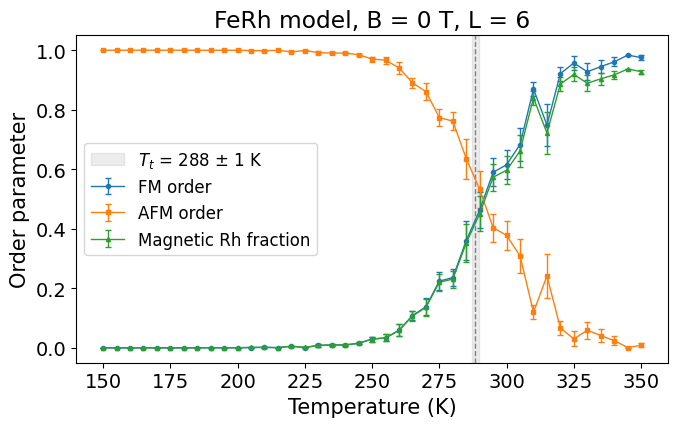

In [12]:
mean0 = scans[0].mean(axis=0)                                  # B=0, 실행 평균
se0 = scans[0].std(axis=0, ddof=1) / np.sqrt(len(seeds))       # 표준오차

fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ["FM order", "AFM order", "Magnetic Rh fraction"]
markers = ["o", "s", "^"]
for q in range(3):
    ax.errorbar(temperatures, mean0[:, q], yerr=se0[:, q], fmt=markers[q] + "-",
                markersize=3, capsize=2, linewidth=1, label=labels[q])

Tt0_mean = np.nanmean(T_t[0])
Tt0_se = np.nanstd(T_t[0], ddof=1) / np.sqrt(np.sum(~np.isnan(T_t[0])))
ax.axvline(Tt0_mean, color="gray", linestyle="--", linewidth=1)
ax.axvspan(Tt0_mean - Tt0_se, Tt0_mean + Tt0_se, color="gray", alpha=0.15,
           label=f"$T_t$ = {Tt0_mean:.0f} ± {Tt0_se:.0f} K")
ax.set(xlabel="Temperature (K)", ylabel="Order parameter",
       title=f"FeRh model, B = 0 T, L = {L}")
ax.set_ylim(-0.05, 1.05)
ax.legend()
fig.tight_layout()
plt.savefig("figures/fig2_order_vs_T.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 11. 결과 ②: 자기장이 $T_t$를 낮춘다

질문에 대한 답이다. 자기장마다 10번 실행한 $T_t$의 평균 ± 표준오차를 그리고, 비교를 위해 실험 기울기(약 −8 K/T, Maat et al. 2005)를 $B=0$의 $T_t$에서 출발하는 점선으로 같이 그린다.

- 자기장을 걸수록 $T_t$가 **내려간다** (0 → 3 T에서 약 88 K).
- 모델은 실험보다 **훨씬 크게** 움직인다. 크기를 정량적으로 구하는 방법(약 −24 K/T)은 Step 12, 차이의 원인은 Step 14(한계)에서 다룬다.
- 곡선이 직선이 아닌 이유는 Step 13에서 다룬다.

 B (T) | T_t 평균 ± SE (K)
  0.00 |  288.4 ± 1.2
  0.25 |  288.6 ± 2.1
  0.50 |  284.9 ± 2.1
  0.75 |  278.3 ± 1.1
  1.00 |  272.4 ± 1.7
  1.25 |  266.8 ± 1.1
  1.50 |  258.6 ± 1.0
  1.75 |  250.2 ± 1.3
  2.00 |  247.1 ± 1.1
  2.25 |  235.2 ± 1.3
  2.50 |  226.8 ± 1.3
  2.75 |  214.0 ± 1.6
  3.00 |  200.8 ± 2.1

0 T → 3 T: T_t = 288 K → 201 K (-88 K)


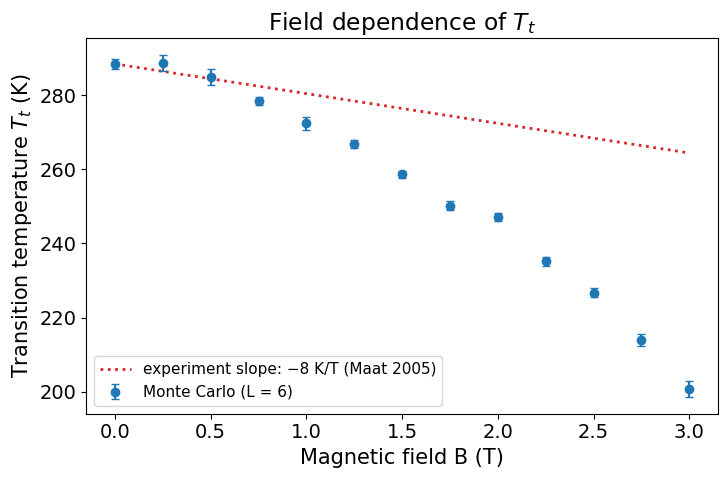

In [13]:
Tt_mean = np.nanmean(T_t, axis=1)
Tt_se = np.nanstd(T_t, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(T_t), axis=1))
EXP_SLOPE = -8.0   # K/T, Maat et al. (2005)

print(" B (T) | T_t 평균 ± SE (K)")
for B, m, e in zip(fields, Tt_mean, Tt_se):
    print(f"{B:6.2f} | {m:6.1f} ± {e:.1f}")
print(f"\n0 T → 3 T: T_t = {Tt_mean[0]:.0f} K → {Tt_mean[-1]:.0f} K ({Tt_mean[-1] - Tt_mean[0]:+.0f} K)")

B_line = np.linspace(0, 3, 121)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.errorbar(fields, Tt_mean, yerr=Tt_se, fmt="o", color="C0", capsize=3, ms=6,
            label=f"Monte Carlo (L = {L})", zorder=5)
ax.plot(B_line, Tt_mean[0] + EXP_SLOPE * B_line, ":", color="C3", lw=2,
        label="experiment slope: −8 K/T (Maat 2005)")       # 실험 기울기를 모델의 T_t(0)에서 출발
ax.set(xlabel="Magnetic field B (T)", ylabel="Transition temperature $T_t$ (K)",
       title="Field dependence of $T_t$")
ax.legend(fontsize=11, loc="lower left")
fig.tight_layout()
plt.savefig("figures/fig3_Tt_vs_B_mc_exp.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 12. 해석 ①: 왜 자기장이 $T_t$를 낮추는가?

**자유에너지로 보기.** 자기장 $B$가 있을 때 안정한 상태는 **자유에너지 $G = U - TS - BM$이 낮은 상태**다. 에너지 $U$만이 아니라 엔트로피 $S$(얼마나 다양하게 흔들릴 수 있는가)와 자화 $M$까지 따진다.

- 저온: $U$가 낮은 **AFM**이 이긴다.
- 고온: $S$가 큰 **FM**이 이긴다. FM에서는 Rh 모멘트를 끄는 비용(약 5.9 mRy)이 AFM에서 켜는 비용(11.1 mRy)의 절반쯤이라 Rh가 훨씬 잘 흔들리기 때문이다.
- 자기장: $M$이 있는 **FM에만** $-BM$ 이득을 준다(AFM은 전체 자화 0).

두 상태의 $G$가 같아지는 온도가 전이온도다.
$$\Delta G = \Delta U - T\Delta S - B\Delta M = 0 \quad\Rightarrow\quad T_t(B)=\frac{\Delta U - B\,\Delta M}{\Delta S},\qquad \frac{dT_t}{dB}=-\frac{\Delta M}{\Delta S}$$
($\Delta$ = FM − AFM. 마지막 식이 자성 Clausius–Clapeyron 관계다.) $\Delta S>0$, $\Delta M>0$이므로 기울기는 음수, 즉 **자기장이 $T_t$를 낮춘다.**

**크기를 시뮬레이션으로 구하기.** $B=0$, $T=T_t$에서 오래 시뮬레이션하면 작은 격자는 AFM과 FM 사이를 계속 오간다. 매 표본마다 $m_{FM}>m_{AF}$이면 "FM 상태", 아니면 "AFM 상태"로 분류하고, 각 상태의 평균 에너지와 평균 자화를 따로 구한다.
- $\Delta U$, $\Delta M$: 두 상태의 평균 에너지 차이와 자화 차이 (칸 하나당)
- $\Delta S$: $T_t$에서는 $\Delta G=0$이므로 $\Delta S = \Delta U / T_t$로 구한다. (그래서 $\Delta U/\Delta S = T_t$는 정의상 성립하는 관계이고, 독립적인 확인은 아니다.)
- 이렇게 $B=0$에서만 잰 $\Delta M$, $\Delta S$로 **자기장 기울기를 예측**한다. 이 예측이 자기장을 실제로 건 시뮬레이션(Step 11)과 맞는지는 Step 13에서 확인한다.

이 기울기는 **무한히 큰 결정**에서 자기장이 작을 때의 기울기에 해당한다. 실험(큰 시료)과 비교할 값은 이것이다.

In [14]:
@njit
def phase_resolved_averages(fe, rh, T, B, seed, n_equil, n_samples):
    # 반환: [상태(0=AFM, 1=FM), (표본 수, 에너지 합, |자화| 합)]
    np.random.seed(seed)
    N_cell = fe.shape[0] ** 3
    for _ in range(n_equil):
        mc_sweep(fe, rh, T, B)
    totals = np.zeros((2, 3))
    for _ in range(n_samples):
        for _ in range(2):
            mc_sweep(fe, rh, T, B)
        m_fm, m_af, rh_fraction = order_parameters(fe, rh)
        energy = total_energy(fe, rh, B) / N_cell                              # 셀당 에너지 (mRy)
        magnet = abs(MU_FE * fe.sum() + MU_RH * rh.sum()) / N_cell             # 셀당 |자화| (mu_B)
        phase = 1 if m_fm > m_af else 0
        totals[phase, 0] += 1
        totals[phase, 1] += energy
        totals[phase, 2] += magnet
    return totals


T_cc = round(Tt_mean[0])          # B=0 전이온도 근처에서 계산
cc_runs = []
for seed in seeds:
    fe, rh = make_afm_state(L)
    t = phase_resolved_averages(fe, rh, T_cc, 0.0, seed + 42, 1000, 20000)
    fm_fraction = t[1, 0] / (t[0, 0] + t[1, 0])
    dU = t[1, 1] / t[1, 0] - t[0, 1] / t[0, 0]          # mRy
    dM = t[1, 2] / t[1, 0] - t[0, 2] / t[0, 0]          # mu_B
    dS = dU / T_cc                                       # mRy/K
    predicted_slope = -dM * MUB_MRY_PER_T / dS           # K/T
    cc_runs.append([fm_fraction, dU, dM, dS / KB_MRY_PER_K, predicted_slope])
cc_runs = np.array(cc_runs)
cc_mean = cc_runs.mean(axis=0)
cc_se = cc_runs.std(axis=0, ddof=1) / np.sqrt(len(seeds))

names = ["FM 상태 비율", "ΔU (mRy/셀)", "ΔM (μB/셀)", "ΔS (kB/셀)", "예측 기울기 (K/T)"]
for name, m, e in zip(names, cc_mean, cc_se):
    print(f"{name:14s}: {m:8.3f} ± {e:.3f}")

# 참고: 실험 기울기(-8 K/T)를 내려면 필요한 엔트로피 (ΔM은 그대로 둠). 결과 파일에만 저장
dS_needed = cc_mean[2] * MUB_MRY_PER_T / (-EXP_SLOPE) / KB_MRY_PER_K
print(f"\nT = {T_cc} K에서 계산")
print(f"ΔU = {cc_mean[1] / KB_MRY_PER_K:.0f} K,  ΔS = ΔU / T_t = {cc_mean[3]:.3f} kB,  ΔM × (1 T) = {cc_mean[2] * MUB_MRY_PER_T / KB_MRY_PER_K:.2f} K  (칸 하나당)")
print(f"무한 결정의 기울기 dT_t/dB = −ΔM/ΔS = {cc_mean[4]:.1f} ± {cc_se[4]:.1f} K/T")

np.savez("ferh_clausius_clapeyron.npz", T_cc=T_cc, runs=cc_runs, dS_needed=dS_needed)

FM 상태 비율      :    0.434 ± 0.010
ΔU (mRy/셀)    :    0.209 ± 0.000
ΔM (μB/셀)     :    4.055 ± 0.000
ΔS (kB/셀)     :    0.115 ± 0.000
예측 기울기 (K/T)  :  -23.717 ± 0.055

T = 288 K에서 계산
ΔU = 33 K,  ΔS = ΔU / T_t = 0.115 kB,  ΔM × (1 T) = 2.72 K  (칸 하나당)
무한 결정의 기울기 dT_t/dB = −ΔM/ΔS = -23.7 ± 0.1 K/T


**정리.** $B=0$에서 잰 값만으로 예측한 기울기는 **−23.7 K/T**(1 T당 약 24 K)다. 자기장 1 T가 FM에 주는 이득(칸당 약 2.7 K)을 엔트로피 차이(0.115 $k_B$)로 나눈 값이다. 발표 슬라이드의 자유에너지 그림은 이 결과(`ferh_clausius_clapeyron.npz`)로 그렸다.

## Step 13. 해석 ②: 왜 곡선이 직선이 아닌가?

Step 12의 식은 $\Delta U$, $\Delta S$, $\Delta M$이 일정하다고 가정하면 직선이다. 곡선은 이 가정이 깨지는 곳이다. 자기장 구간을 셋으로 나눠 볼 수 있다.

| 구간 | 모양 | 원인 |
|---|---|---|
| 0 – 0.5 T | 평평함 | 자기장이 아직 너무 약해, FM 방향을 잡아주지 못한 상태 |
| 0.5 – 2 T | 거의 직선 | $\Delta U$, $\Delta S$, $\Delta M$이 거의 일정 → 식 그대로 (약 −24 K/T) |
| 2 T 이상 | 더 가파름 | $\Delta S$가 크게 줄어듦 (추정) |

- **0 – 0.5 T:** 자기장이 매우 약하면, 작은 격자 안에서 FM의 $+M$ 방향과 $-M$ 방향이 모두 샘플링된다. 그래서 자기장이 실제로 이용하는 평균 $\Delta M$이 작고, $dT_t/dB=-\Delta M/\Delta S$에 따라 초반 기울기도 작다.
- **0.5 – 2 T:** 자기장이 FM 방향을 충분히 골라 주고 $\Delta M/\Delta S$가 거의 일정해서, 약 −24 K/T의 거의 직선 구간이 된다.
- **2 T 이상:** 기울기의 절댓값이 다시 커진다. $\Delta S$가 줄어 $\Delta M/\Delta S$가 커지는 것으로 추정하지만, 아직 직접 확인하지 않았으므로 기말에 확인한다.

**(1) 세 구간 그림.** 위 표의 구간 경계(0.5 T, 2 T)를 세로 점선으로 표시한다.

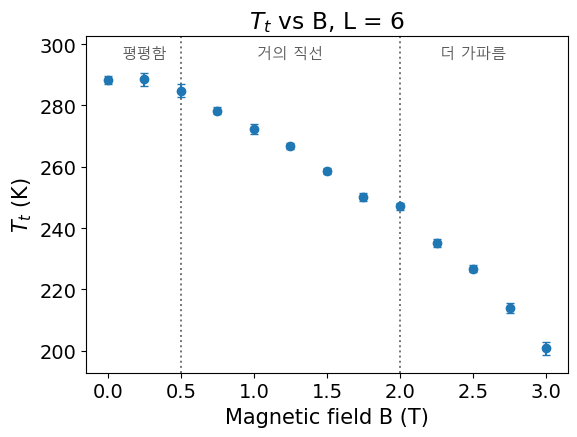

In [15]:
# 위 표의 세 구간(0–0.5 T, 0.5–2 T, 2 T 이상)을 세로 점선으로 나눈 그림
regions = [(0.25, "평평함"), (1.25, "거의 직선"), (2.5, "더 가파름")]     # (구간 가운데 B, 이름)
from matplotlib import font_manager
installed = {f.name for f in font_manager.fontManager.ttflist}
korean_font = [f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic"] if f in installed][:1] + ["DejaVu Sans"]
# ↑ 설치된 한글 글꼴 하나 (Windows / Mac / Colab 순) + 한글 글꼴에 없는 기호(− 등)는 기본 글꼴로

for labeled in (True, False):
    fig, ax = plt.subplots(figsize=(6, 4.6))
    ax.errorbar(fields, Tt_mean, yerr=Tt_se, fmt="o", color="C0", capsize=3, zorder=3)
    for b in [0.5, 2.0]:
        ax.axvline(b, color="0.45", ls=":", lw=1.4, zorder=1)
    ax.set(xlabel="Magnetic field B (T)", ylabel="$T_t$ (K)", title=f"$T_t$ vs B, L = {L}")
    ax.set_xlim(-0.15, 3.15)
    top = Tt_mean.max() + 14
    ax.set_ylim(Tt_mean.min() - 8, top)
    if labeled:
        for x, name in regions:
            ax.text(x, top - 3, name, ha="center", va="top", fontsize=11, color="0.35", fontfamily=korean_font)
    fig.tight_layout()
    plt.savefig("figures/fig3a_Tt_vs_B_regions" + ("" if labeled else "_nolabel") + ".png",
                dpi=300, bbox_inches="tight", facecolor="white")
    if labeled:
        plt.show()
    else:
        plt.close(fig)       # 구간 이름이 없는 버전은 파일로만 저장

**(2) 구간별 기울기.** 표의 세 구간마다, 실행별로 직선을 맞춘 기울기의 평균 ± 표준오차를 구해 "모양" 열을 숫자로 확인한다.

In [16]:
# 슬라이드 표의 세 구간마다, 실행별로 직선을 맞춘 기울기 → 평균 ± SE
segments = [(0.0, 0.5, "평평함"), (0.5, 2.0, "거의 직선"), (2.0, 3.0, "더 가파름")]
print(" 구간 (T)   | 모양      | 기울기 (K/T)")
for lo, hi, name in segments:
    part = (fields >= lo - 1e-9) & (fields <= hi + 1e-9)          # 경계 점은 양쪽 구간에 모두 포함
    slopes = [np.polyfit(fields[part], T_t[part, r], 1)[0] for r in range(len(seeds))]
    print(f" {lo:.1f} – {hi:.1f}  | {name:6s} | {np.mean(slopes):6.1f} ± {np.std(slopes, ddof=1) / np.sqrt(len(slopes)):.1f}")
print(f"\n비교: Step 12에서 B = 0 값만으로 예측한 −ΔM/ΔS = {cc_mean[4]:.1f} K/T")

 구간 (T)   | 모양      | 기울기 (K/T)
 0.0 – 0.5  | 평평함    |   -7.0 ± 5.7
 0.5 – 2.0  | 거의 직선  |  -26.2 ± 1.3
 2.0 – 3.0  | 더 가파름  |  -45.5 ± 2.2

비교: Step 12에서 B = 0 값만으로 예측한 −ΔM/ΔS = -23.7 K/T


**결과 읽기**
- **0 – 0.5 T:** 기울기가 약 −7 K/T로 작다(점이 3개뿐이라 오차도 크다).
- **0.5 – 2 T:** 약 −26 K/T로, Step 12에서 $B=0$ 값만으로 예측한 −23.7 K/T와 비슷하다. 이 구간에서는 식 그대로 움직인다.
- **2 T 이상:** 약 −46 K/T로 훨씬 가파르다. $\Delta S$가 줄어든 것으로 추정하지만 아직 직접 확인하지 않았으므로, 기말에 낮은 온도에서 $\Delta S$를 재서 확인한다.

## Step 14. 한계, 결론, 다음 단계

### 한계
| 한계 | 영향 |
|---|---|
| **실험보다 기울기 약 3배** (−24 vs −8 K/T) | 스핀만 있는 모델 → 전자·격자 엔트로피 고려하지 않음 |
| 작은 격자 ($L\le8$) | $L=8$ 가열에서 갇힘 · $L\ge10$ 미확인 |
| 높은 자기장 (> 2 T) | 더 가파른 이유는 추정 단계 ($\Delta S$ 감소) |

**가장 큰 한계: 실험과의 차이.** 모델은 자기장 효과를 실험보다 약 3배 크게 예측한다. 기울기는 $\Delta M/\Delta S$로 정해지는데, $\Delta M$은 실제 원자 모멘트 값을 썼으므로 크게 틀리지 않는다. 반면 이 모델은 스핀 자유도만 포함하고, 실제 FeRh 전이에 기여하는 **전자와 격자 진동(포논)의 엔트로피**(Cooke et al. 2012)를 포함하지 않는다. 따라서 모델의 $\Delta S$가 실제보다 작아 기울기가 과대평가된 것으로 해석할 수 있다. 그 밖에 이번 계산은 작은 격자에 한정되어 있고($L\ge10$은 현재 샘플링 방법으로 평형화하지 못함), 2 T 이상의 급격한 기울기 변화의 원인은 아직 가설 단계다.

### 결론
- 자기장은 자화가 있는 FM에만 에너지 이득을 줘서 $T_t$를 낮춘다.
- 크기 = $\Delta M/\Delta S$ → 이 모델에서 1 T당 약 24 K (무한 결정, −23.7 K/T).
- 검증: 에너지 계산(Step 7), $L=2$ 엄밀해(Step 8).

### 다음 단계 (기말)
1. 빠진 엔트로피(전자·격자) 추가 → 실험(−8 K/T)에 가까워지는가?
2. 더 좋은 샘플링 → $L\ge10$에서 무한 결정의 기울기를 직접 확인
3. 박막 효과(변형·두께) → 실제 데이터와 비교

### 참고문헌
1. M. E. Gruner, E. Hoffmann, P. Entel, *Phys. Rev. B* **67**, 064415 (2003) — 모델과 매개변수
2. S. Maat, J.-U. Thiele, E. E. Fullerton, *Phys. Rev. B* **72**, 214432 (2005) — 실험 $dT_t/dB$
3. J. S. Kouvel, C. C. Hartelius, *J. Appl. Phys.* **33**, 1343 (1962) — 벌크 FeRh 전이
4. N. Metropolis et al., *J. Chem. Phys.* **21**, 1087 (1953) — Metropolis 알고리즘
5. W. K. Hastings, *Biometrika* **57**, 97 (1970) — 일반화된 제안 방식 (집단 이동)
6. C. J. Lewis, C. H. Marrows, S. Langridge, *J. Phys. D* **49**, 323002 (2016) — FeRh 리뷰
7. J. A. Cooke et al., *Phys. Rev. Lett.* **109**, 255901 (2012) — 전이의 열역학 측정
8. J. Barker, R. W. Chantrell, *Phys. Rev. B* **92**, 094402 (2015) — Heisenberg형 FeRh 모델